# Selección de modelos OLS · propiedades usadas

[1. Datos](#1.-Datos) · [2. Forward Selection](#2.-Forward-Selection) · [3. Group Lasso + OLS](#3.-Group-Lasso-+-OLS) · [4. Comparación final](#4.-Comparación-final)

## 1. Datos
Se utiliza exclusivamente `data/train_transformado.csv`, generado en `2_Transformacion_PropUsadas.ipynb`: **177 columnas predictoras exportadas → 174 candidatas**, tras excluir `to_center_km`, `living_area` y `rooms`.
Las exclusiones se centralizan en `s.EXCLUIDAS`; `EXCLUIDAS=()` habilita las 177, pero exige nueva selección y nombres de Run nuevos: los modelos históricos se rechazan si cambia la configuración.
El objetivo es `ln(price_rub)`; las predicciones en RUB usan `exp` sin corrección de sesgo. No se repite la preparación del CSV y Test permanece reservado.
Ambos métodos comparten la partición interna fija 80/20 de Train (semilla 42). El OLS definitivo conserva las columnas transformadas exportadas.
El grupo original `date_posted_dt` representa la columna derivada `months_since_start`; la fecha auxiliar no entra directamente al modelo.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
paquete = next(c for p in (Path.cwd(), *Path.cwd().parents)
               for c in (p, p / "Ventas/Propiedades_Usadas") if (c / "scripts/__init__.py").is_file())
if str(paquete) not in sys.path: sys.path.insert(0, str(paquete))
from scripts import seleccion_modelos as s
from scripts.almacenamiento_mlflow import SesionTemporal
from scripts.contrato_datasets import CARPETA_PROYECTO as base
EXCLUIDAS, MODO = s.EXCLUIDAS, "recuperar"  # Cambiar a 177 requiere EXCLUIDAS=(), modo nuevo y Runs nuevos.
sesion = SesionTemporal()
with sesion.paso():
    datos = s.cargar_presentacion(base, sesion, excluidas=EXCLUIDAS)
print(f"Observaciones: {len(datos['y']):,} · Candidatas: {datos['n_exportadas']} − {len(EXCLUIDAS)} = {datos['X'].shape[1]} columnas, {len(datos['grupos'])} grupos")
print("Características candidatas: " + ", ".join(datos['grupos']))
print("Objetivo: ln(price_rub)")


Observaciones: 37,984 · Candidatas: 177 − 3 = 174 columnas, 20 grupos
Características candidatas: total_area, kitchen_area, floor, total_floors, building_year, ceiling_height, metro_distance_min, metro_to_center_km, mortgage_key_rate_at_listing, surface_corrected, secondary_mom_change_pct, has_balcony, metro_distance_type, seller_type, building_type, renovation, metro_line, district, date_posted_dt, month_of_year
Objetivo: ln(price_rub)


## 2. Forward Selection
Incorpora progresivamente el grupo que más reduce el RMSE de validación interna en RUB: máximo **12 características**, mejora mínima **0,5 %**.
Cada bloque One-Hot se selecciona completo como una característica original.
El modo actual **recupera la selección y el OLS históricos de MLflow**; `modo="nuevo"` ejecuta el procedimiento y exige un nombre de Run libre mediante `nombre_run`.


In [2]:
with sesion.paso():
    forward = s.ejecutar_presentacion(datos, "forward", modo=MODO)


In [3]:
display(Markdown(forward['caracteristicas_md']))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `district` | 128 |
| `total_area` | 1 |
| `renovation` | 3 |
| `date_posted_dt` | 1 |
| `building_type` | 5 |
| `metro_distance_min` | 1 |
| `metro_distance_type` | 1 |
| Total: 7 características | 140 predictores |

In [4]:
display(Markdown(s.tabla_metricas_presentacion(forward)))


| Evaluación | Métrica | Forward |
|---|---|---|
| Train | R² [ln(RUB)] | 0.953577 |
| Train | R² ajustado [ln(RUB)] | 0.953405 |
| Train | MAE (RUB) | 1,116,830.765 |
| Train | RMSE (RUB) | 1,609,441.446 |
| Train | AIC [ln(RUB)] | -52,883.105 |
| Train | BIC [ln(RUB)] | -51,678.271 |
| Train | VIF máximo | 8.554 |
| Train | Número de condición | 13,160.607 |
| Train | Breusch–Pagan (p) | 2.337e-87 |
| Train | Jarque–Bera (p) | 2.214e-65 |
| Validación interna | RMSE (RUB) | 1,612,615.151 |

In [5]:
display(Markdown(s.interpretar_presentacion(forward)))


El OLS utiliza 7 características originales y 140 columnas predictoras, más el intercepto.  
R² ajustado log=0.95341; RMSE Train=1,609,441 RUB y validación interna=1,612,615 RUB.  
Persisten límites de homocedasticidad (BP p=2.34e-87) y normalidad (JB p=2.21e-65).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

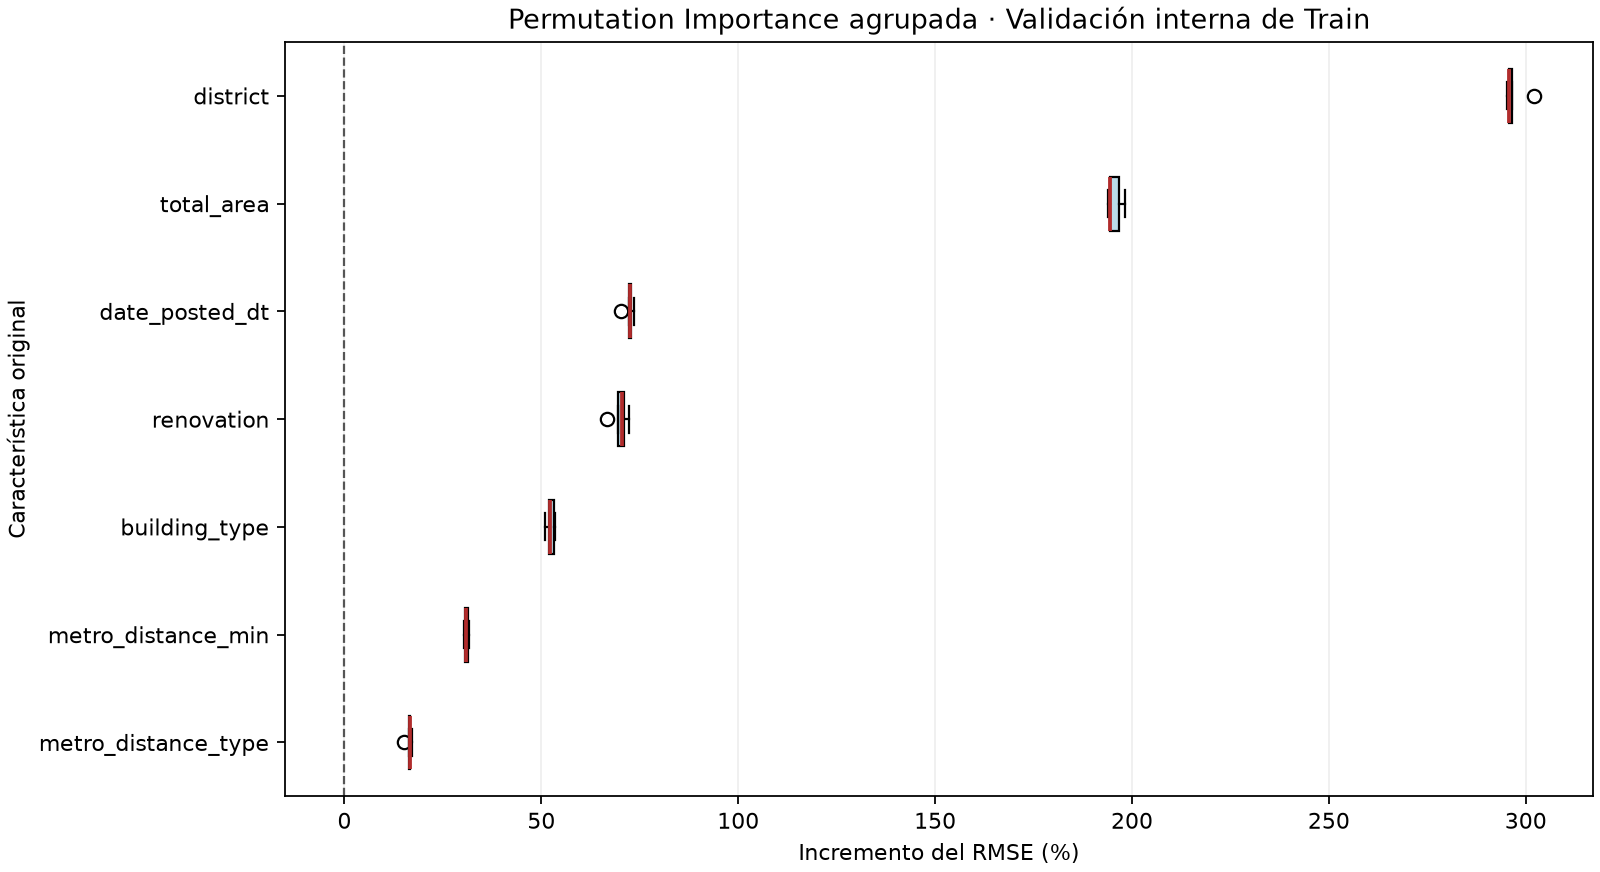

Mayores medianas de incremento del RMSE: `district` (295.7 %), `total_area` (194.5 %), `date_posted_dt` (72.5 %); 5 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [6]:
display(Image(filename=str(forward['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(forward)))


In [7]:
display(Markdown(s.confirmacion_presentacion(forward)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [Forward_01_Log_Grupos](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/d43e88406b0843c5b7963d2c1e62d15a)

## 3. Group Lasso + OLS
La regularización selecciona grupos completos (incluidos los bloques One-Hot); después se ajusta un OLS sin penalización con las características elegidas.
Se evalúan **40 lambdas**, desde λmáx hasta 0,001 × λmáx. Los subconjuntos se comparan por RMSE interno en RUB, con máximo **12 grupos** y mejora mínima **0,5 %** entre complejidades aceptadas; se evalúa la grilla completa.
El escalado propio de la selección se ajusta solo en el entrenamiento interno; el OLS final conserva las escalas exportadas. Se comparte la partición de Forward.
El modo actual **recupera el Run histórico**; `modo="nuevo"` ejecuta la búsqueda y el OLS con un nombre de Run nuevo.


In [8]:
with sesion.paso():
    lasso = s.ejecutar_presentacion(datos, "lasso", modo=MODO, anterior=forward)


In [9]:
display(Markdown(lasso['caracteristicas_md']))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `total_area` | 1 |
| `ceiling_height` | 1 |
| `metro_distance_min` | 1 |
| `metro_to_center_km` | 1 |
| `surface_corrected` | 1 |
| `has_balcony` | 1 |
| `metro_distance_type` | 1 |
| `building_type` | 5 |
| `renovation` | 3 |
| `district` | 128 |
| `date_posted_dt` | 1 |
| Total: 11 características | 144 predictores |

In [10]:
display(Markdown(s.tabla_metricas_presentacion(lasso, anterior=forward)))


| Evaluación | Métrica | Forward | Group Lasso + OLS | Δ nuevo − anterior |
|---|---|---|---|---|
| Train | R² [ln(RUB)] | 0.953577 | 0.954765 | 0.001188 |
| Train | R² ajustado [ln(RUB)] | 0.953405 | 0.954592 | 0.001187 |
| Train | MAE (RUB) | 1,116,830.765 | 1,104,234.841 | -12,595.924 |
| Train | RMSE (RUB) | 1,609,441.446 | 1,592,884.139 | -16,557.307 |
| Train | AIC [ln(RUB)] | -52,883.105 | -53,859.677 | -976.572 |
| Train | BIC [ln(RUB)] | -51,678.271 | -52,620.664 | -942.393 |
| Train | VIF máximo | 8.554 | 10.369 | 1.815 |
| Train | Número de condición | 13,160.607 | 13,237.461 | 76.854 |
| Train | Breusch–Pagan (p) | 2.337e-87 | 8.128e-117 | -2.337e-87 |
| Train | Jarque–Bera (p) | 2.214e-65 | 2.745e-51 | 2.745e-51 |
| Validación interna | RMSE (RUB) | 1,612,615.151 | 1,593,947.716 | -18,667.436 |

In [11]:
display(Markdown(s.interpretar_presentacion(lasso, anterior=forward)))


El OLS utiliza 11 características originales y 144 columnas predictoras, más el intercepto.  
R² ajustado log=0.95459; RMSE Train=1,592,884 RUB y validación interna=1,593,948 RUB.  
Frente a Forward, cambia +4 características y el RMSE interno -1.158 %; no simplifica el modelo.  
Persisten límites de homocedasticidad (BP p=8.13e-117) y normalidad (JB p=2.75e-51).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

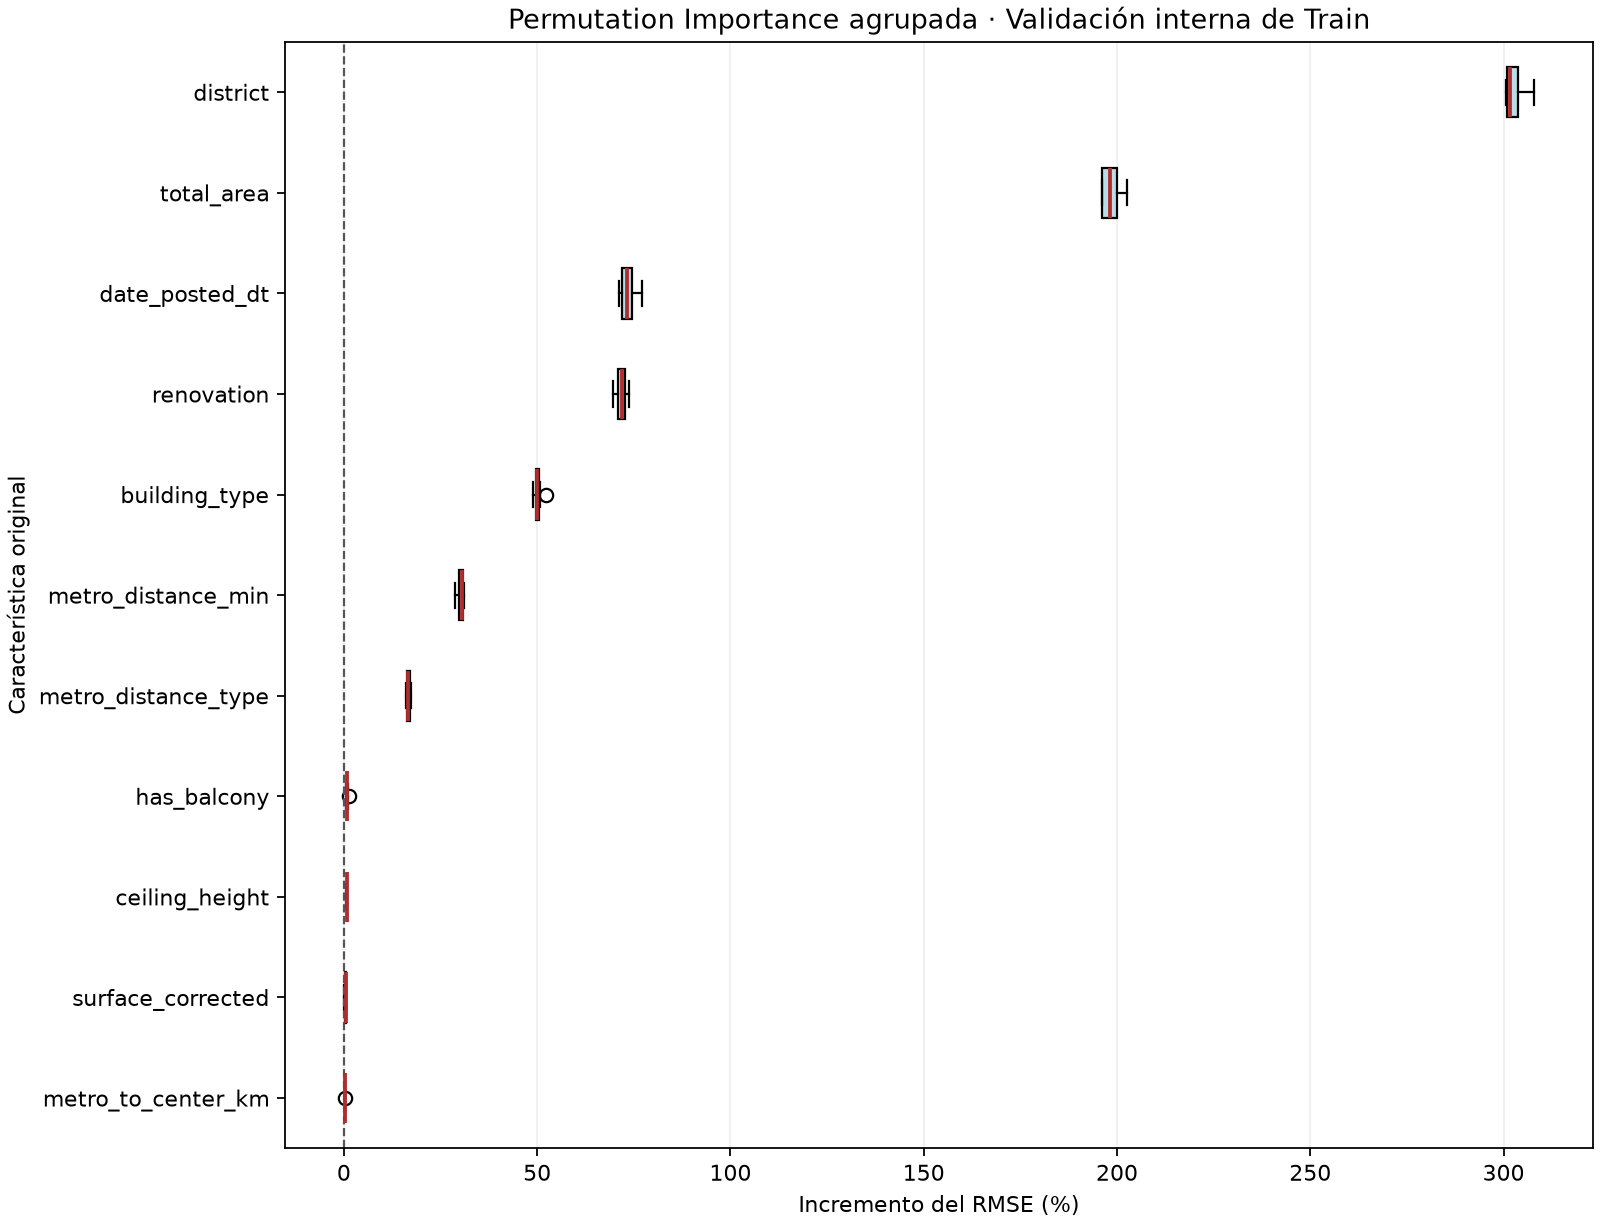

Mayores medianas de incremento del RMSE: `district` (301.7 %), `total_area` (198.3 %), `date_posted_dt` (73.3 %); 10 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [12]:
display(Image(filename=str(lasso['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(lasso)))


In [13]:
display(Markdown(s.confirmacion_presentacion(lasso)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [GroupLasso_02_Log_Grupos_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/ac9faf6b61db4a7f8e274553199c5658)

## 4. Comparación final
R² ajustado, AIC y BIC corresponden a `ln(price_rub)` sobre las mismas filas de Train. Los RMSE se expresan en RUB y distinguen Train de validación interna.


In [14]:
tabla_final, coincidencias = s.comparacion_final_presentacion(forward, lasso)
display(Markdown(tabla_final))
display(Markdown(coincidencias))


| Método | Características | Columnas OLS | R² ajustado Train [log] | RMSE Train (RUB) | RMSE interno (RUB) | AIC [log] | BIC [log] |
|---|---|---|---|---|---|---|---|
| Forward Selection | 7 | 140 | 0.953405 | 1,609,441.446 | 1,612,615.151 | -52,883.105 | -51,678.271 |
| Group Lasso + OLS | 11 | 144 | 0.954592 | 1,592,884.139 | 1,593,947.716 | -53,859.677 | -52,620.664 |

Coinciden: `building_type`, `date_posted_dt`, `district`, `metro_distance_min`, `metro_distance_type`, `renovation`, `total_area`.  
Exclusivas de Forward: Ninguna.  
Exclusivas de Group Lasso: `ceiling_height`, `has_balcony`, `metro_to_center_km`, `surface_corrected`.

In [15]:
display(Markdown(s.conclusion_presentacion(forward, lasso)))
sesion.cerrar()


Group Lasso + OLS obtuvo el menor RMSE en la validación interna compartida; Forward Selection logró la mayor reducción de características.  
AIC y BIC son comparables porque ambos OLS ajustan ln(price_rub) sobre las mismas filas con la misma convención.  
La comparación reutiliza la validación empleada en la selección; no prueba superioridad fuera de muestra ni define el modelo final. Test no se utilizó.